# Regressão Logística nos dados covtype de LIBSVM

Iremos treinar os dados para classificação binária usando os dados `covtype` da biblioteca [LIBSVM](https://www.csie.ntu.edu.tw/~cjlin/libsvm/). Veja também [Kaggle-LIBSVM](https://www.kaggle.com/code/tanmayunhale/libsvm-liblinear).

Queremos minimizar

$$
\min_{w\in {\mathbb R}^{d\times1}} f(w)=-\frac{1}{n}\sum_{i=1}^n \left(y_i \log (s(x_i^\top w)) + (1 - y_i) \log (1 - s(x_i^\top w))\right) + \frac{\gamma}{2}\|w\|^2,
$$

onde $x_i\in {\mathbb R}^{d\times1}$, $y_i\in \{0, 1\}$, $s(z)=\frac{1}{1+\exp(-z)}$ é a função sigmóide. O gradiente é dado por

$$
\nabla f(w) = \frac{1}{n}\sum_{i=1}^n x_i(s(x_i^\top w)-y_i) + \gamma w.
$$

Esta é uma função suave com constante de Lipschitz $L=L_0+\gamma$ onde

$$
L_0 = \frac{1}{4}\lambda_{\max}\left(\frac{X^\top X}{n}\right),
$$ 

onde $X\in\mathbb{R}^{n\times d}$ é a matriz de dados cuja $i$-ézima linha é o vetor $x_i^\top$ e $\lambda_{\max}(\cdot)$ denota o maior autovalor.

In [1]:
# Importação de módulos necesserários:

import matplotlib
import numpy as np
import scipy
import seaborn as sns
import matplotlib.pyplot as plt
import numpy.linalg as la
from sklearn.datasets import load_svmlight_file
from sklearn.utils.extmath import safe_sparse_dot

In [2]:
# Lendo os dados do arquivo covtype e guardando na matriz de dados X e vetor de labels y:

X, y = load_svmlight_file('./covtype.bz2')
if (np.unique(y) == [1, 2]).all():
    # Devemos garantir que os labels estão em {0, 1}
    y -= 1    
    
n, d = X.shape # tamanho da amostra, número de features    

# Exercício 1: Funções auxiliares

1. Construa uma função `smoothness(X)` que toma a matriz de dados `X` e retorna a constante $L_0$.
2. Construa uma função `f(w, X, y, l2)` que toma o iterado `w`, os dados `X, y` e a penalização $\gamma$ (=`l2`) e retorna o valor funcional $f(w)$.
3. Construa uma função `df(w, X, y, l2)` toma o iterado `w`, os dados `X, y` e a penalização $\gamma$ (=`l2`) e retorna o gradiente $\nabla f(w)$.

In [3]:
#Escreva código aqui
def smoothness(X: np.ndarray) -> float: 
    G = ((X.T @ X) / X.shape[0]).toarray() 
    return la.eigvalsh(G)[-1] / 4

def sigmoid(a: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-a))

def f(w: np.ndarray, X: np.ndarray, y: np.ndarray, l2: float) -> float:
    z = sigmoid(X @ w)

    perda = (-1 / X.shape[0]) * (y * np.log(z) + (1 - y) * np.log(1 - z)).sum()
    regularizacao = (l2 / 2) * la.norm(w) ** 2

    return perda + regularizacao

def df(w: np.ndarray, X: np.ndarray, y: np.ndarray, l2: float) -> np.ndarray: 
    z = sigmoid(X @ w)

    perda = (X.T @ (z - y)) / X.shape[0]
    regularizacao = l2 * w

    return perda + regularizacao

# Inicialização

Fixaremos:

In [4]:
L0 = smoothness(X)
l2 = L0 / n
L = L0 + l2
w0 = np.zeros(d)        # ponto inicial
it_max = 10000          # número de iterações

#Função de desempenho é a norma de Frobenius:
J = lambda w: la.norm(w)

#Função que retorna gradiente (para X,y,l2) já declarados.
def Df(w):
    return df(w, X, y, l2)

l2

np.float64(8.676367672880712)

# Exercício 2: Método do gradiente

Construa uma função `gd(df, w0, la=1, numb_iter=100)` que toma como entrada as funções `J()` `df()`, o ponto inicial `w0`, o passo `la` e o número de iterações `numb_iter` e implementa o método gradiente iniciando de `w0`. Esta função deve retornar a sequência de valores da função $\Vert\nabla f(w)\Vert_2$ em cada um dos iterados $w$. A função também deve retornar o último iterado. 

Implemente a função com passo `la=1./L` 

In [5]:
#Escreva código aqui

# Note que a assinatura da função apresentada no enunciado não possui J, entretanto, o texto da a entender 
# que deveria estar presente. A chamada de gd(...) na célula abaixo também da a enender o mesmo
# Apesar disso, 

def gd(J, Df, w0: np.ndarray, la: float = 1, numb_iter: int = 100) -> tuple[np.ndarray, np.ndarray]:
    wk = w0.copy()

    norms = np.zeros(numb_iter + 1)
    grad = Df(wk)
    norms[0] = J(grad) 

    for epoch in range(numb_iter):
        wk -= la * grad
        grad = Df(wk)
        norms[epoch+1] = J(grad)

    return norms, wk

In [6]:
# gradient descent
f1 = gd(J, Df, w0, la=1./L, numb_iter=it_max)

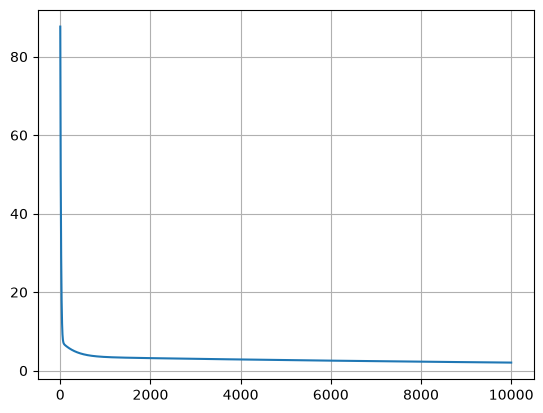

In [7]:
plt.plot(f1[0])
plt.grid(True)

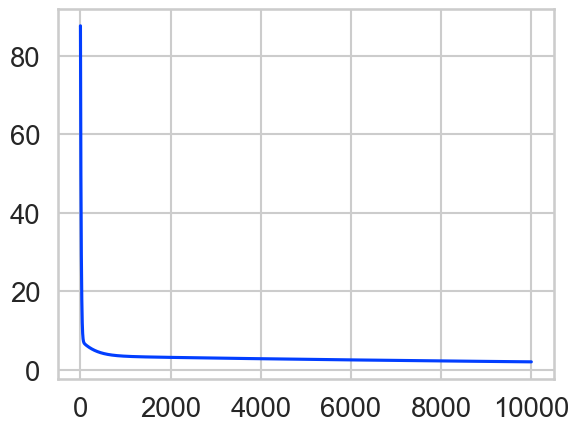

In [ ]:
# Resultado original
plt.plot(f1[0])

# Exercício 3: Método do gradiente acelerado

Construa uma função `accel_gd(J, df, w0, la=1, numb_iter=100)` que toma como entrada as funções `J()`, `df()`, o ponto inicial `w0`, o passo `la` e o número de iterações `numb_iter` e implementa o método gradiente com aceleração de Nesterov iniciando de `w0` e $t_0=1$:
\begin{align*}
w_{k+1}&:= y_k - la\nabla f(y_k),\\
t_{k+1} &:= \frac{1+\sqrt{1+4t_k^2}}{2},\\
y_{k+1} &:= w_{k+1} + \frac{t_{k}-1}{t_{k+1}}(w_{k+1}-w_{k}).
\end{align*}
Esta função deve retornar a sequência de valores da função `J(df(y))` em cada um dos iterados `y`, isto é, a sequência das normas dos gradientes de $y_k$ ao longo da trajetória do método. A função também deve retornar o último iterado. 

Implemente a função com passo `la=1./L`.

In [8]:
#Escreva código aqui
def accel_gd(J, df, w0: np.ndarray, la: float = 1, numb_iter: int = 100) -> tuple[np.ndarray, np.ndarray]:
    wk = w0.copy()
    tk = 1
    yk = w0.copy()

    wk1 = yk - la * df(yk)
    tk1 = (1 + (1 + 4*tk**2) ** (1/2)) / 2

    norms = np.zeros(numb_iter + 1)
    grad = df(yk)
    norms[0] = J(grad)
    
    for epoch in range(numb_iter):
        yk = wk1 + (wk1 - wk)*(tk - 1)/tk1
        grad = df(yk)
        norms[epoch+1] = J(grad)

        wk = wk1
        tk = tk1

        wk1 = yk - la * grad
        tk1 = (1 + (1 + 4*tk**2) ** (1/2)) / 2

    return norms, wk1

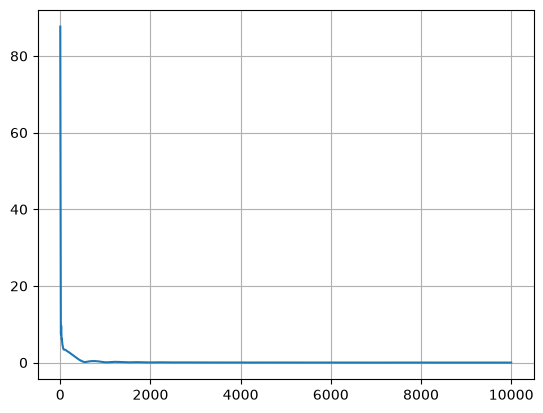

In [9]:
# Nesterov accelerated gradient descent
f2 = accel_gd(J, Df, w0, la=1./L, numb_iter=it_max)
plt.plot(f2[0])
plt.grid(True)

Time execution for accelerated AGD: 842.4450372909196


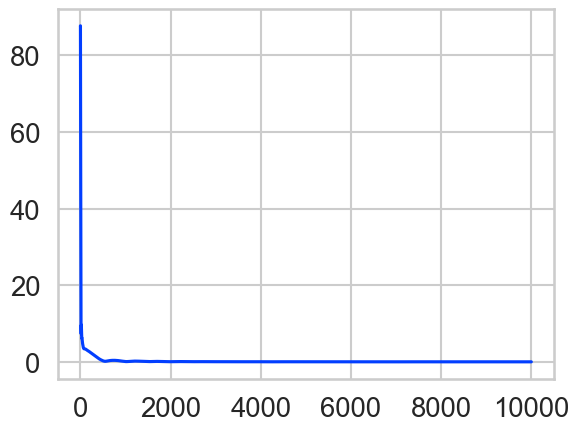

In [ ]:
# Resultado original
# Nesterov accelerated gradient descent
f2 = accel_gd(J, Df, w0, la=1./L, numb_iter=it_max)
plt.plot(f2[0])

# Exercício 4: Método do gradiente acelerado com $\gamma$

Construa uma função `accel_gd_sc(J, df, w0, la=1, kappa, numb_iter=100)` que toma como entrada as funções `J()`, `df()`, o ponto inicial `w0`, o passo `la` e o número de iterações `numb_iter` e implementa o método gradiente com aceleração de Nesterov iniciando de `y0=w0`:
\begin{align*}
w_{k+1}&:= y_k - la\nabla f(y_k),\\
y_{k+1} &:= w_{k+1} + \frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}(w_{k+1}-w_{k}).
\end{align*}
Àcima, $\kappa:=L/\gamma$. Esta função deve retornar a sequência de valores da função `J(df(y))` em cada um dos iterados `y`, isto é, a sequência das normas dos gradientes de $y_k$ ao longo da trajetória do método. A função também deve retornar o último iterado. 

Implemente a função com passo `la=1./L`.

In [ ]:
#Escreva código aqui
def accel_gd_sc(J, Df, w0: np.ndarray, la: float = 1, kappa: float = L/l2, numb_iter: int = it_max) -> tuple[np.ndarray, np.ndarray]:
    wk = w0.copy()
    yk = w0.copy()

    grad = Df(yk)
    wk1 = yk - la * grad

    norms = np.zeros(numb_iter + 1)
    norms[0] = J(grad)
    c = (kappa**(1/2) - 1)/(kappa**(1/2) + 1)

    for epoch in range(numb_iter):
        yk = wk1 + (wk1 - wk) * c
        grad = Df(yk)
        norms[epoch+1] = J(grad)

        wk = wk1

        wk1 = yk - la * grad

    return norms, wk1

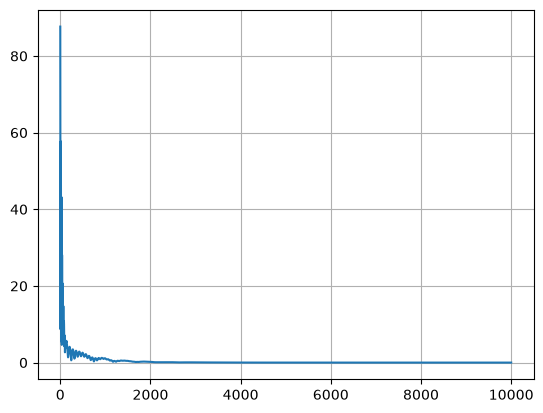

In [11]:
# Nesterov accelerated gradient descent for strongly convex functions
f3 = accel_gd_sc(J, Df, w0, la=1./L, kappa=L/l2, numb_iter=it_max)
plt.plot(f3[0])
plt.grid(True)

Time execution for accelerated AGD-SC: 818.4171042499365


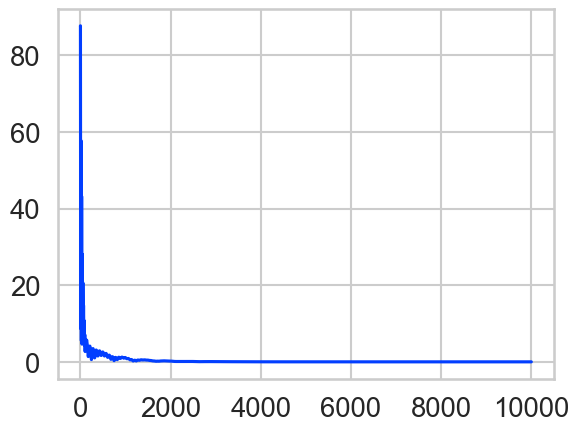

In [ ]:
# Resultado original
# Nesterov accelerated gradient descent for strongly convex functions
f3 = accel_gd_sc(J, Df, w0, la=1./L, kappa=L/l2, numb_iter=it_max)
plt.plot(f3[0])

# Exercício 5: Adagrad-Norm

Construa uma função `ad_grad_norm(J, Df, w0, b0=0.5, eta=1, numb_iter=100)` que toma como entrada as funções `J()`, `Df`, o ponto inicial `w0`, parametros positivos `b0` e `eta` e o número de iterações `numb_iter` e implementa o método Adagrad-Norm iniciando de `w0`:
\begin{align*}
w_{k+1}&:= w_k - \frac{\eta}{\sqrt{b_0^2 + \sum_{j=1}^k\Vert\nabla f(w_j)\Vert_2^2}} \nabla f(w_k).
\end{align*}
Esta função deve retornar a sequência de valores da função `J(Df(w))` em cada um dos iterados `w`, isto é, a sequência das normas dos gradientes de $X_k$ ao longo da trajetória do método. A função também deve retornar o último iterado. 

Implemente a função com `b0=0.5` e `eta=1`.

In [63]:
#Escreva código aqui
def ad_grad_norm(J, Df, w0: np.ndarray, b0: float = 0.5, eta: float = 1, numb_iter: int = 100) -> tuple[np.ndarray, np.ndarray]:
    wk = w0.copy()

    norms = np.zeros(numb_iter + 1)
    grad = Df(wk)
    norms[0] = J(grad)
    norm_sum = la.norm(grad) ** 2

    for epoch in range(numb_iter):
        wk = wk - eta / (b0 ** 2 + norm_sum) ** (1/2) * grad
        grad = Df(wk)
        norms[epoch+1] = J(grad)
        norm_sum += norms[epoch+1] ** 2

    return norms, wk

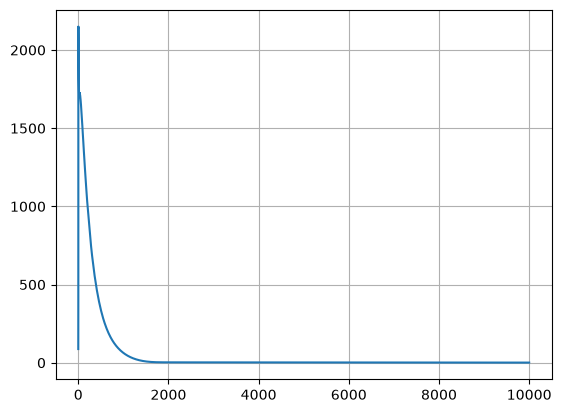

In [13]:
# Adagrad-Norm
f4 = ad_grad_norm(J, Df, w0, b0=0.5, eta=0.01, numb_iter=it_max)
plt.plot(f4[0])
plt.grid(True)

Time execution for GD: 1487.6604519160464


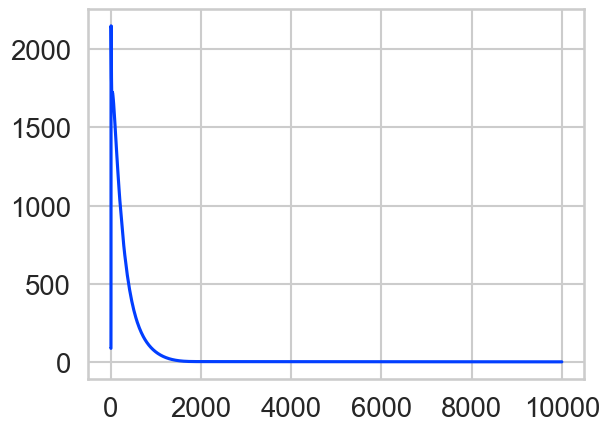

In [ ]:
# Resultado original
# Adagrad-Norm
f4 = ad_grad_norm(J, Df, w0, b0=0.5, eta=0.01, numb_iter=it_max)
plt.plot(f4[0])

# Exercício 6: Adam

Construa uma função `adam(Df, w0, alpha, beta1, beta2, epsilon, numb_iter)` que toma como entrada as funções `Df`, o ponto inicial `w0`, parametros positivos `alpha`, `beta1`, `beta2`, `epsilon` e o número de iterações `numb_iter` e implementa o método Adam iniciando de `w0`, $m_0=0$, $v_0=0$ e $k=0$: para cada $j$ézima coordenada:
\begin{align*}
m_{k+1}[j] &:= \beta_1\cdot m_{k}[j] + (1-\beta_1)\cdot\nabla f(w_k)[j],\\
v_{k+1}[j] &:= \beta_2\cdot v_{k}[j] + (1-\beta_2)\cdot(\nabla f(w_k)[j])^2,\\
\hat m_{k+1}[j] &:= \frac{1}{1-\beta_1^{k+1}}m_{k+1}[j],\\
\hat v_{k+1}[j] &:= \frac{1}{1-\beta_2^{k+1}}v_{k+1}[j],\\
w_{k+1}[j] &:= w_{k}[j] - \frac{\alpha}{\sqrt{\hat v_{k+1}[j]} + \epsilon }\hat m_{k+1}[j].
\end{align*}
Esta função deve retornar a sequência de valores da função `J(Df(w))` em cada um dos iterados `w`, isto é, a sequência das normas dos gradientes de $w_k$ ao longo da trajetória do método. A função também deve retornar o último iterado. 

Implemente a função com `alpha=0.001`, `beta1=0.9`, `beta2=0.999`, `epsilon=10**(-8)`. 

In [14]:
# O enunciado exige o retorno de J(Df(w)), logo, foi necessário alterar a assinatura especificada

#Escreva código aqui
def adam(J, Df, w0: np.ndarray, alpha: float = 0.001, beta1: float = 0.9, beta2: float = 0.999, epsilon: float = 10**(-8), numb_iter: int = 100)  -> tuple[np.ndarray, np.ndarray]:
    wk = w0.copy()
    mk = np.zeros_like(wk)
    vk = np.zeros_like(wk)
    beta1k = beta1
    beta2k = beta2

    mk_hat = mk / (1-beta1k)
    vk_hat = vk / (1-beta2k) 

    norms = np.zeros(numb_iter + 1)
    grad = Df(wk)
    norms[0] = J(grad)

    for epoch in range(numb_iter):
        wk = wk - alpha * mk_hat / (vk_hat ** (1/2) + epsilon)
        grad = Df(wk)
        norms[epoch+1] = J(grad)

        mk = beta1 * mk + (1 - beta1) * grad
        vk = beta2 * vk + (1 - beta2) * grad ** 2

        beta1k *= beta1
        beta2k *= beta2
        mk_hat = mk / (1-beta1k)
        vk_hat = vk / (1-beta2k) 

    return norms, wk

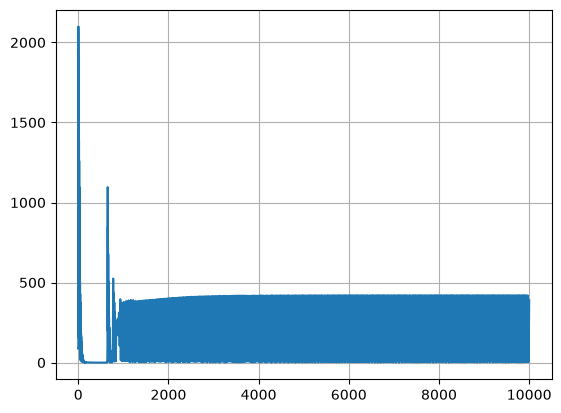

In [15]:
# Adam
f5 = adam(J, Df, w0, alpha=0.001, beta1=0.9, beta2=0.999, epsilon=10**(-8), numb_iter=it_max)
plt.plot(f5[0])
plt.grid(True)

Time execution for Adam: 2356.390969166998


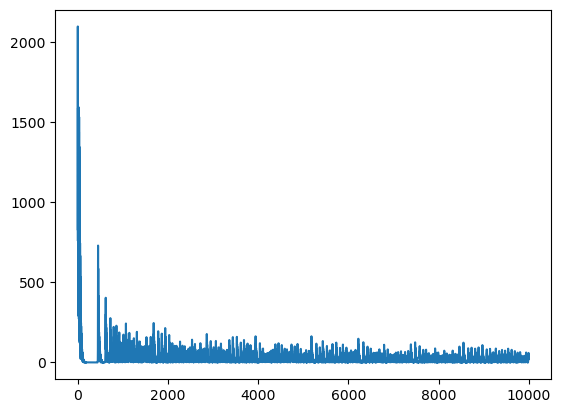

In [ ]:
# Resultado original
# Adam
f5 = adam(J, Df, w0, alpha=0.001, beta1=0.9, beta2=0.999, epsilon=10**(-8), numb_iter=it_max)
plt.plot(f5[0])

# Exercício 7: 

Implemente num mesmo gráfico os erros $\Vert\nabla f(w_k)\Vert$ de cada método em função no número de iterações.

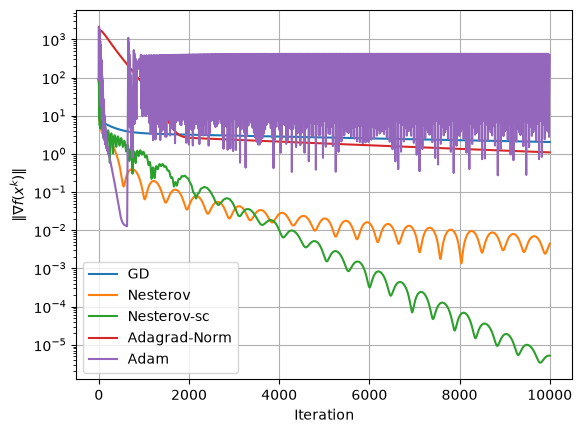

In [16]:
# Escreva código aqui
plt.plot(f1[0], label='GD')
plt.plot(f2[0], label='Nesterov')
plt.plot(f3[0], label='Nesterov-sc')
plt.plot(f4[0], label='Adagrad-Norm')
plt.plot(f5[0], label='Adam')

plt.xlabel('Iteration')
plt.ylabel(r'$\|\nabla f(x^k)\|$')
plt.yscale('log')
plt.legend()
plt.grid(True)

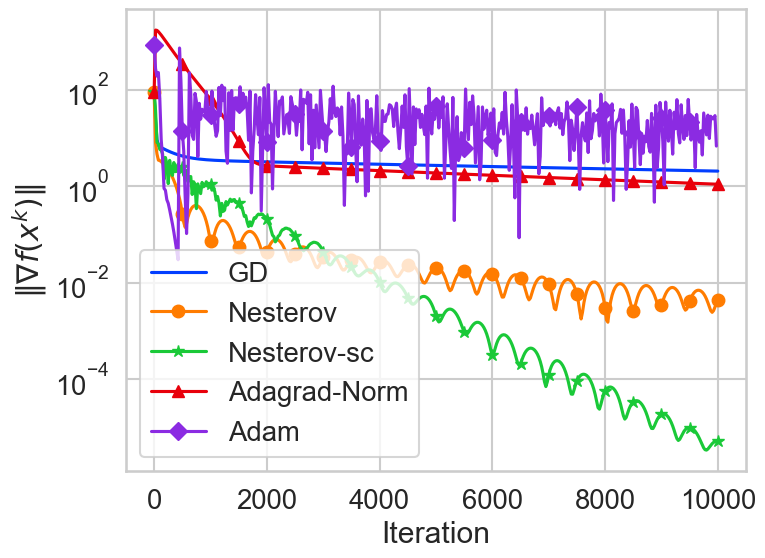

In [ ]:
# Resultado original

# Exercício 8:

Experimente com os hyper-parâmetros de Adagrad-Norm and Adam para ver se eles podem chegar perto ou superar a performance de GD e Nesterov. Plote o gráfico como no Exercício 7. 

In [98]:
# setup 
import pandas as pd

# parametros gerais
test_iter = 1000

# adagrad: eta e acumulador inicial
eta_search = np.logspace(-4, -2, num=3)
b0_search = np.linspace(0, 1, num=5)

# adam:primeiro e segundo momento
lr_search = np.logspace(-6, -3, num=3)
beta1_search = 1 - np.logspace(-2, -1, num=2)
beta2_search = 1 - np.logspace(-4, -2, num=3)
# epsilon garante estabilidade numérica, o que não é o problema no momento (não vemos NaN)

print('Parametros de busca: ')
print('eta:\t', eta_search)
print('b0:\t', b0_search)
print('lr:\t', lr_search)
print('beta1:\t', beta1_search)
print('beta2:\t', beta2_search)

Parametros de busca: 
eta:	 [0.0001 0.001  0.01  ]
b0:	 [0.   0.25 0.5  0.75 1.  ]
lr:	 [1.00000000e-06 3.16227766e-05 1.00000000e-03]
beta1:	 [0.99 0.9 ]
beta2:	 [0.9999 0.999  0.99  ]


In [99]:
# busca do adagrad

adagrad_results = list()
for eta in eta_search:
    for b0 in b0_search:
        norms, w = ad_grad_norm(J, Df, w0, b0, eta, test_iter)
        adagrad_results.append({
            'eta': eta,
            'b0': b0,
            'last_norm': norms[-1],
            'median_norm_total': np.median(norms),
            'median_norm_10pct': np.mean(norms[int(test_iter*0.9):]),
            'avg_norm_total': np.mean(norms),
            'avg_norm_10pct': np.mean(norms[int(test_iter*0.9):])
        })

adagrad_df = pd.DataFrame(adagrad_results)

In [100]:
adagrad_best_idx = adagrad_df['avg_norm_10pct'].idxmin()
adagrad_best_avg = adagrad_df.iloc[adagrad_best_idx]
adagrad_best_avg

eta                   0.001000
b0                    0.000000
last_norm             3.190796
median_norm_total     3.455469
median_norm_10pct     3.209123
avg_norm_total       12.343229
avg_norm_10pct        3.209123
Name: 5, dtype: float64

In [101]:
adagrad_best_idx = adagrad_df['median_norm_10pct'].idxmin()
adagrad_best_med = adagrad_df.iloc[adagrad_best_idx]
adagrad_best_med

eta                   0.001000
b0                    0.000000
last_norm             3.190796
median_norm_total     3.455469
median_norm_10pct     3.209123
avg_norm_total       12.343229
avg_norm_10pct        3.209123
Name: 5, dtype: float64

In [103]:
# treinamento completo com os melhores hiperparametros encontrados

adagrad_final_avg = ad_grad_norm(J, Df, w0, adagrad_best_avg.b0, adagrad_best_avg.eta, it_max)

In [ ]:
# são iguais
# adagrad_final_med = ad_grad_norm(J, Df, w0, adagrad_best_med.b0, adagrad_best_med.eta, it_max)

KeyboardInterrupt: 

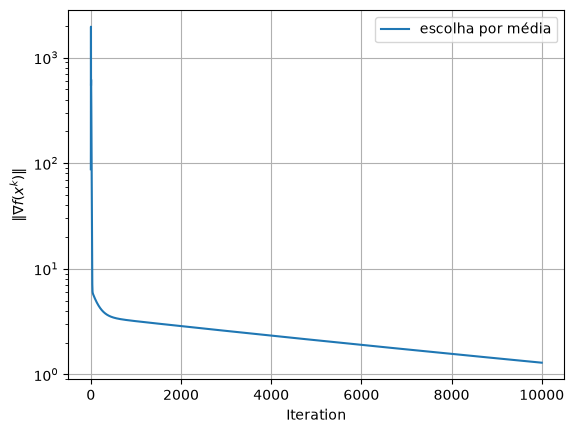

In [104]:
plt.plot(adagrad_final_avg[0], label='escolha por média')
#plt.plot(adagrad_final_med[0], label='escolha por mediana')

plt.xlabel('Iteration')
plt.ylabel(r'$\|\nabla f(x^k)\|$')
plt.yscale('log')
plt.legend()
plt.grid(True)

In [105]:
# busca do adam

adam_results = list()
for lr in lr_search:
    for b1 in beta1_search:
        for b2 in beta2_search:
            norms, w = adam(J, Df, w0, lr, b1, b2, numb_iter=test_iter)
            adam_results.append({
                'lr': lr,
                'b1': b1,
                'b2': b2,
                'last_norm': norms[-1],
                'median_norm_total': np.median(norms),
                'median_norm_10pct': np.mean(norms[:test_iter-int(test_iter/10)]),
                'avg_norm_total': np.mean(norms),
                'avg_norm_10pct': np.mean(norms[:test_iter-int(test_iter/10)])
            })

adam_df = pd.DataFrame(adam_results)

In [106]:
adam_best_idx = adam_df['avg_norm_10pct'].idxmin()
adam_best_avg = adam_df.iloc[adam_best_idx]
adam_best_avg

lr                   0.000032
b1                   0.900000
b2                   0.999900
last_norm            9.848111
median_norm_total    0.467158
median_norm_10pct    2.735746
avg_norm_total       2.493930
avg_norm_10pct       2.735746
Name: 9, dtype: float64

In [107]:
adam_best_idx = adam_df['median_norm_10pct'].idxmin()
adam_best_med = adam_df.iloc[adam_best_idx]
adam_best_med

lr                   0.000032
b1                   0.900000
b2                   0.999900
last_norm            9.848111
median_norm_total    0.467158
median_norm_10pct    2.735746
avg_norm_total       2.493930
avg_norm_10pct       2.735746
Name: 9, dtype: float64

In [110]:
# treinamento completo com os melhores hiperparametros encontrados

adam_final_avg = adam(J, Df, w0, adam_best_avg.lr, adam_best_avg.b1, adam_best_avg.b2, numb_iter=it_max)

In [ ]:
# ficaram iguais tbm
# adam_final_med = adam(J, Df, w0, adam_best_med.lr, adam_best_med.b1, adam_best_med.b2, it_max)

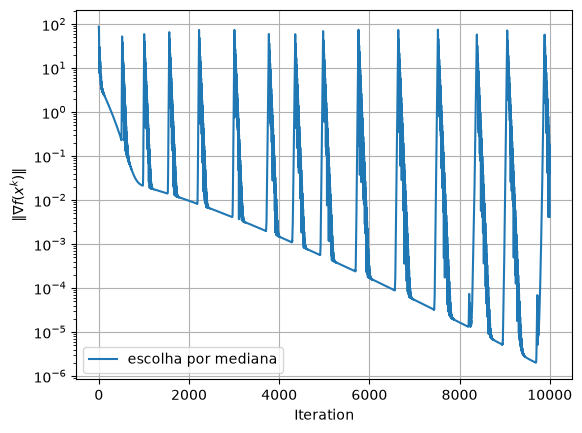

In [111]:
# plt.plot(adam_final_med[0], label='escolha por média')
plt.plot(adam_final_avg[0], label='escolha por mediana')

plt.xlabel('Iteration')
plt.ylabel(r'$\|\nabla f(x^k)\|$')
plt.yscale('log')
plt.legend()
plt.grid(True)

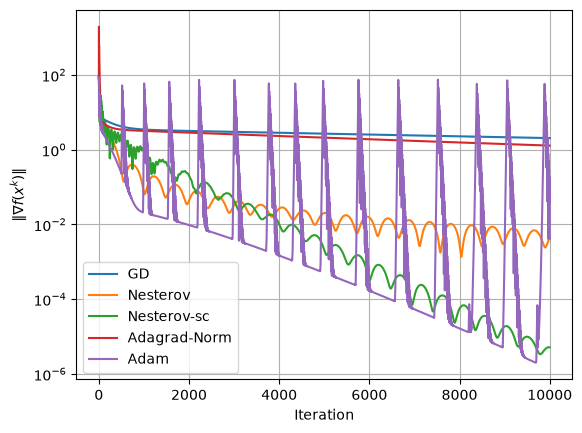

In [112]:
plt.plot(f1[0], label='GD')
plt.plot(f2[0], label='Nesterov')
plt.plot(f3[0], label='Nesterov-sc')
plt.plot(adagrad_final_avg[0], label='Adagrad-Norm')
plt.plot(adam_final_avg[0], label='Adam')

plt.xlabel('Iteration')
plt.ylabel(r'$\|\nabla f(x^k)\|$')
plt.yscale('log')
plt.legend()
plt.grid(True)